# Zephyr Snow Predictor

Copyright 2026 by [Doulos](https://www.doulos.com)

Licensed under the Apache License, Version 2.0 (the "License"); you may not use this file except in compliance with the License. You may obtain a copy of the License at:\
http://www.apache.org/licenses/LICENSE-2.0

Unless required by applicable law or agreed to in writing, software distributed under the License is distributed on an "AS IS" BASIS, WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied. See the License for the specific language governing permissions and limitations under the License.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/doulos/ESE24-edgeAI/blob/main/1_CollectData.ipynb)

## Part1- Getting the Data

Install in your virtual environment the required Python packages (*wetterdienst*). \
Not needed if the packages are already installed.

In [12]:
import os
from pathlib import Path

if os.getenv("COLAB_RELEASE_TAG"):
    !pip install wetterdienst

#!pip install wetterdienst

### Verify Data Access
To verify that we can access the weather data with *wetterdienst*, run the example programs that shows (location, elevation) for all German weather stations.

**Note**: In my case (windows 11, python 3.14, laptop behind a firewall), I need set the settings to use the certifi certificate bundle instead of system certificates. Otherwise, the  call to `DwdObservationRequest` fails with a SSL error, see: [SSL certificate verification issues](https://wetterdienst.readthedocs.io/en/latest/known_issues.html#ssl-certificate-verification-issues).

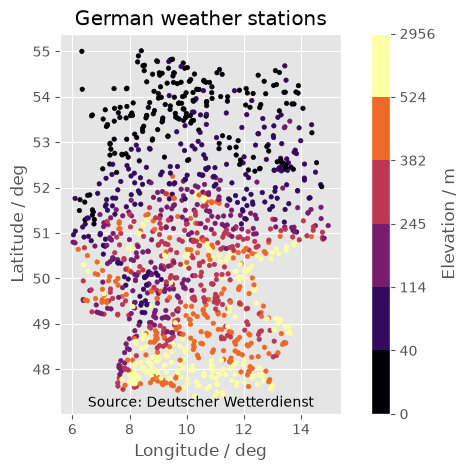

In [13]:
# taken from:
# https://github.com/earthobservations/wetterdienst/blob/v0.172.0/examples/provider/dwd/observation/dwd_obs_plot_german_weather_stations.py
#
# Copyright (C) 2018-2025, earthobservations developers.
# Distributed under the MIT License. See LICENSE for more info.
#
"""Plot German weather stations."""

import math

import matplotlib.pyplot as plt
from matplotlib import colors
from matplotlib.colors import ListedColormap

from wetterdienst.provider.dwd.observation import (
    DwdObservationRequest,
)
from wetterdienst import Settings

plt.style.use("ggplot")

def plot_german_weather_stations() -> None:
    """Create map of DWD weather stations in Germany."""
    settings = Settings(use_certifi=True)
    stations = DwdObservationRequest(parameters=("daily", "climate_summary"), periods="historical", settings=settings)
    stations_df = stations.all().df
    fig, ax = plt.subplots()
    quantiles = [0.0, 0.16666667, 0.33333333, 0.5, 0.66666667, 0.83333333, 1.0]
    bounds = [stations_df["elevation"].quantile(q) for q in quantiles]
    inferno = plt.get_cmap("inferno")
    cmap = ListedColormap([inferno(q) for q in quantiles])
    norm = colors.BoundaryNorm(bounds, cmap.N)
    plot = ax.scatter(data=stations_df, x="longitude", y="latitude", c="elevation", s=10, cmap=cmap, norm=norm)
    fig.colorbar(plot, ax=ax, label="Elevation / m")
    ax.set_xlabel("Longitude / deg")
    ax.set_ylabel("Latitude / deg")
    ax.set_title("German weather stations")
    # make Germany look like Germany by using the proper scaling between y-axis and x-axis
    # 51 is approximately the mean latitude of Germany
    ax.set_aspect(1 / math.cos(51 * math.pi / 180))
    ax.text(0.5, 0.01, "Source: Deutscher Wetterdienst", ha="center", va="bottom", transform=ax.transAxes)
    fig.tight_layout()
    plt.show()

plot_german_weather_stations()

### Request Weather Data

Request historical data for German weather stations:
- temperature, humidity, precipitation form and precipitation amount
- resolution hourly
- from 1st Jan 2001 to 31 Dec 2025 (25 years)

The available data/parameters depends on the time resolution. The `precipitation_form` (that indicates if the precipitation's type, like snow or rain) is only available in the hourly resolution.

In [14]:
# these import are not needed if you ran the previous cell
# but they don't hurt either! (as import are cached in sys.modules)
#
import datetime as dt

from wetterdienst.provider.dwd.observation import DwdObservationRequest
from wetterdienst import (Options,Settings)

In [15]:
settings = Settings(use_certifi=True)

options = Options(
    humanize=True,       # use human-redable name for features, instead of the technical DWD code
    convert_units=False, # prefer Celsius and millimeters over Kelvin and meters
)

In [16]:
resolution="hourly"
request = DwdObservationRequest(
    parameters=[(resolution, "temperature_air", "temperature_air_2m"), 
                (resolution, "temperature_air", "humidity_relative"),
                (resolution, "precipitation", "precipitation_form"),
                (resolution, "precipitation", "precipitation_amount"),

               ],
    start=dt.datetime(2001, 1, 1),
    end=dt.datetime(2026, 1, 1),
    settings=settings,
    options = options
    )

### Locate the Stations close to the Electronica-Fair 
locate all stations in a 20-km radius from Munich-Riem using latitude/longitude

In [17]:
munich_riem = (48.1308, 11.6857)
close_stations = request.filter_by_distance(latlon=munich_riem, distance=30).df

We print the first 6 rows:
- `temperature_air` dataset is available for Munich-Riem (stationId=3390), from 1st Jan 1949 to 17 May 1992.
- The `precipitation` dataset is not available. Thus: we cannot use this station.
- Even if it were available, the time period could skew the predictor due to climate change.

We choose stationId 3379 (Munich city) which has both dataset available from 1997 to now.

**Fun fact**: The airport in Munich was previously located here, at the Munich-Fair trade center. The airport closed on 16 May 1992, see this [wikipedia article](https://en.wikipedia.org/wiki/Munich-Riem_Airport).

In [18]:
close_stations[:6]

resolution,dataset,station_id,start_timestamp,end_timestamp,latitude,longitude,elevation,name,region,distance
str,str,str,"datetime[μs, UTC]","datetime[μs, UTC]",f64,f64,f64,str,str,f64
"""hourly""","""temperature_air""","""03390""",1949-01-01 00:00:00 UTC,1992-05-17 00:00:00 UTC,48.1369,11.7094,529.0,"""München-Riem""","""Bayern""",1.8851
"""hourly""","""temperature_air""","""03382""",1948-01-01 00:00:00 UTC,1954-01-01 00:00:00 UTC,48.1441,11.6,521.0,"""München-Bogenhausen""","""Bayern""",6.5291
"""hourly""","""temperature_air""","""03379""",1997-07-01 00:00:00 UTC,2026-11-11 00:00:00 UTC,48.1632,11.5429,515.0,"""München-Stadt""","""Bayern""",11.1904
"""hourly""","""precipitation""","""03379""",1997-07-07 00:00:00 UTC,2026-11-12 00:00:00 UTC,48.1632,11.5429,515.0,"""München-Stadt""","""Bayern""",11.1904
"""hourly""","""precipitation""","""01366""",2006-01-10 00:00:00 UTC,2026-11-12 00:00:00 UTC,48.2213,11.7989,498.0,"""Finsing""","""Bayern""",13.1043
"""hourly""","""precipitation""","""00933""",2003-04-28 00:00:00 UTC,2026-11-12 00:00:00 UTC,48.0368,11.5777,585.0,"""Deisenhofen, Kreis München""","""Bayern""",13.1762


### Fetch the data
Fetch the raw observation data and store them to a file. That way, we can work locally.
Polars (and pandas) supports export of dataframe in different format like CSV, Excel and some optimized formats for large data set (efficient storage, faster read/write operation) like HDF5 or parquet. 

In [19]:
station_id = 1262 # munich aiport
# station_id = 3379 # munich-city
station = request.filter_by_station_id(station_id)

In [20]:
raw_df = station.values().all().df
raw_df.write_parquet("raw_dataset.parquet")

Quick look at the data structure. Can serve to double check the data loaded from disk

In [21]:
print(f"""
shape  : {raw_df.shape}
columns: {raw_df.columns},
null   : {raw_df.null_count()}
""")


shape  : (811087, 7)
columns: ['station_id', 'resolution', 'dataset', 'parameter', 'timestamp', 'value', 'quality_flags'],
null   : shape: (1, 7)
┌────────────┬────────────┬─────────┬───────────┬───────────┬───────┬───────────────┐
│ station_id ┆ resolution ┆ dataset ┆ parameter ┆ timestamp ┆ value ┆ quality_flags │
│ ---        ┆ ---        ┆ ---     ┆ ---       ┆ ---       ┆ ---   ┆ ---           │
│ u32        ┆ u32        ┆ u32     ┆ u32       ┆ u32       ┆ u32   ┆ u32           │
╞════════════╪════════════╪═════════╪═══════════╪═══════════╪═══════╪═══════════════╡
│ 0          ┆ 0          ┆ 0       ┆ 0         ┆ 0         ┆ 0     ┆ 0             │
└────────────┴────────────┴─────────┴───────────┴───────────┴───────┴───────────────┘



In [22]:
raw_df.head()

station_id,resolution,dataset,parameter,timestamp,value,quality_flags
str,str,str,str,"datetime[μs, UTC]",f64,str
"""01262""","""hourly""","""precipitation""","""precipitation_amount""",2001-01-01 00:00:00 UTC,0.0,"""1"""
"""01262""","""hourly""","""precipitation""","""precipitation_amount""",2001-01-01 01:00:00 UTC,0.0,"""1"""
"""01262""","""hourly""","""precipitation""","""precipitation_amount""",2001-01-01 02:00:00 UTC,0.0,"""1"""
"""01262""","""hourly""","""precipitation""","""precipitation_amount""",2001-01-01 03:00:00 UTC,0.0,"""1"""
"""01262""","""hourly""","""precipitation""","""precipitation_amount""",2001-01-01 04:00:00 UTC,0.0,"""1"""
